In [33]:
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage

from PIL import Image

In [22]:
best_model_path = "runs/detect/runs/brain_mri/yolov8n_baseline/weights/best.pt"

model = YOLO(best_model_path)

results = model.val(
    data=str(output_path / "data.yaml"),
    split="test",
    imgsz=224,
    batch=16,
    plots=True,
    project="runs/brain_mri",
    name="test_evaluation"
)

Ultralytics 8.4.193 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 11910MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 688.3±332.3 MB/s, size: 17.2 KB)
val: Scanning /data/processed/brain_mri_yolo/labels/test.cache... 949 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 949/949 137.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 13.8it/s 4.3s0.1s
                   all        949       1066      0.934       0.92      0.954      0.729
                Glioma        229        264      0.893       0.86      0.903      0.639
            Meningioma        292        299      0.972      0.953      0.979      0.803
              No Tumor        143        143      0.993      0.993      0.995      0.816
             Pituitary        335        360      0.877      0.873      0.937      0.656
Speed: 0.1ms pr


image 1/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0014.jpg: 224x224 1 Glioma, 19.0ms
image 2/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0026.jpg: 224x224 1 Glioma, 18.6ms
image 3/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0043.jpg: 224x224 1 Glioma, 17.3ms
image 4/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0061.jpg: 224x224 1 Glioma, 1 Pituitary, 16.3ms
image 5/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0063.jpg: 224x224 1 Glioma, 14.8ms
image 6/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0084.jpg: 224x224 1 Glioma, 14.3ms
image 7/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0116.jpg: 224x224 2 Gliomas, 12.9ms
image 8/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0121.jpg: 224x224 1 Glioma, 12.0ms
image 9/949 /data/processed/brain_mri_yolo/images/test/glioma_Te-gl_0138.jpg: 224x224 1 Glioma, 1 Pituitary, 11.1ms
image 10/949 /data/processed/brain_mri_yolo/i

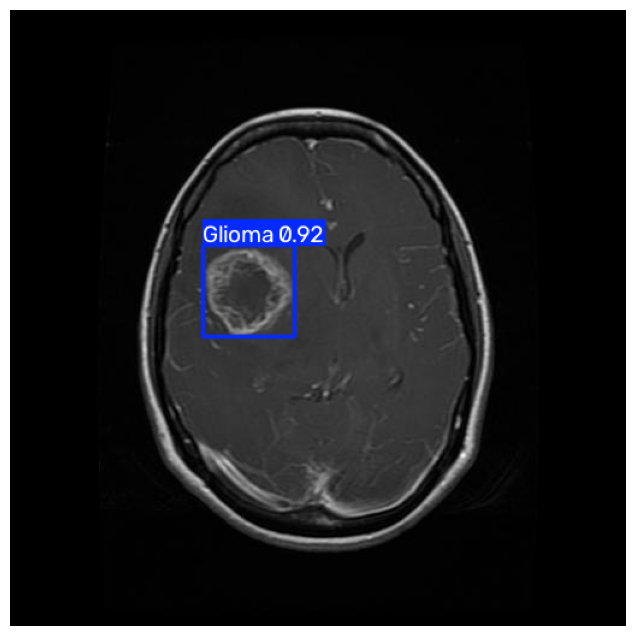

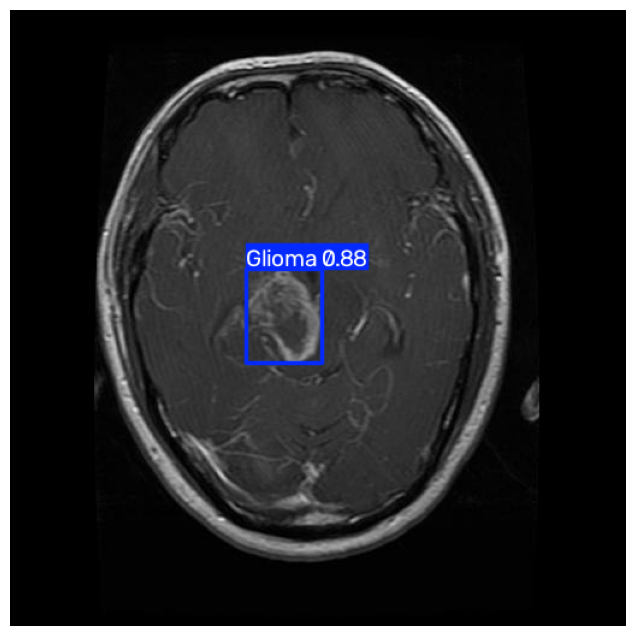

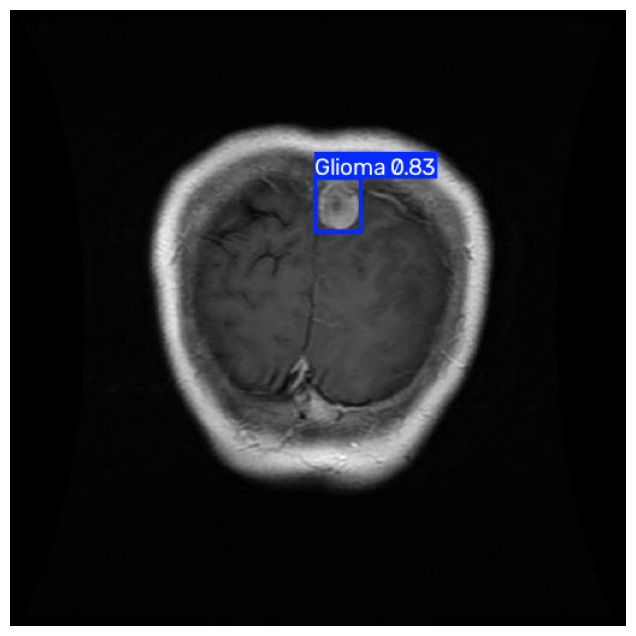

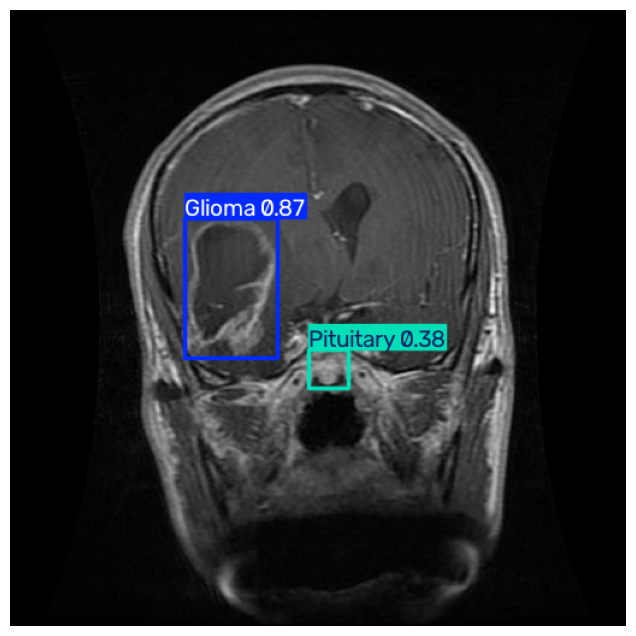

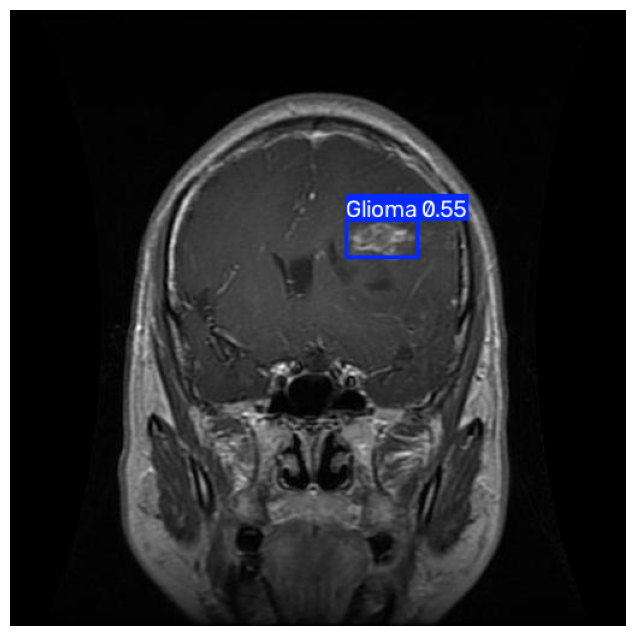

In [25]:
results = model.predict(
    source = str(output_path / "images" / "test"),
    imgsz = 224,
    conf = 0.25,
    save = False,
)

for result in results[:5]:
    plotted_image = result.plot()
    plt.figure(figsize=(8, 8))
    plt.imshow(plotted_image[:, :, ::-1])
    plt.axis("off")
    plt.show()


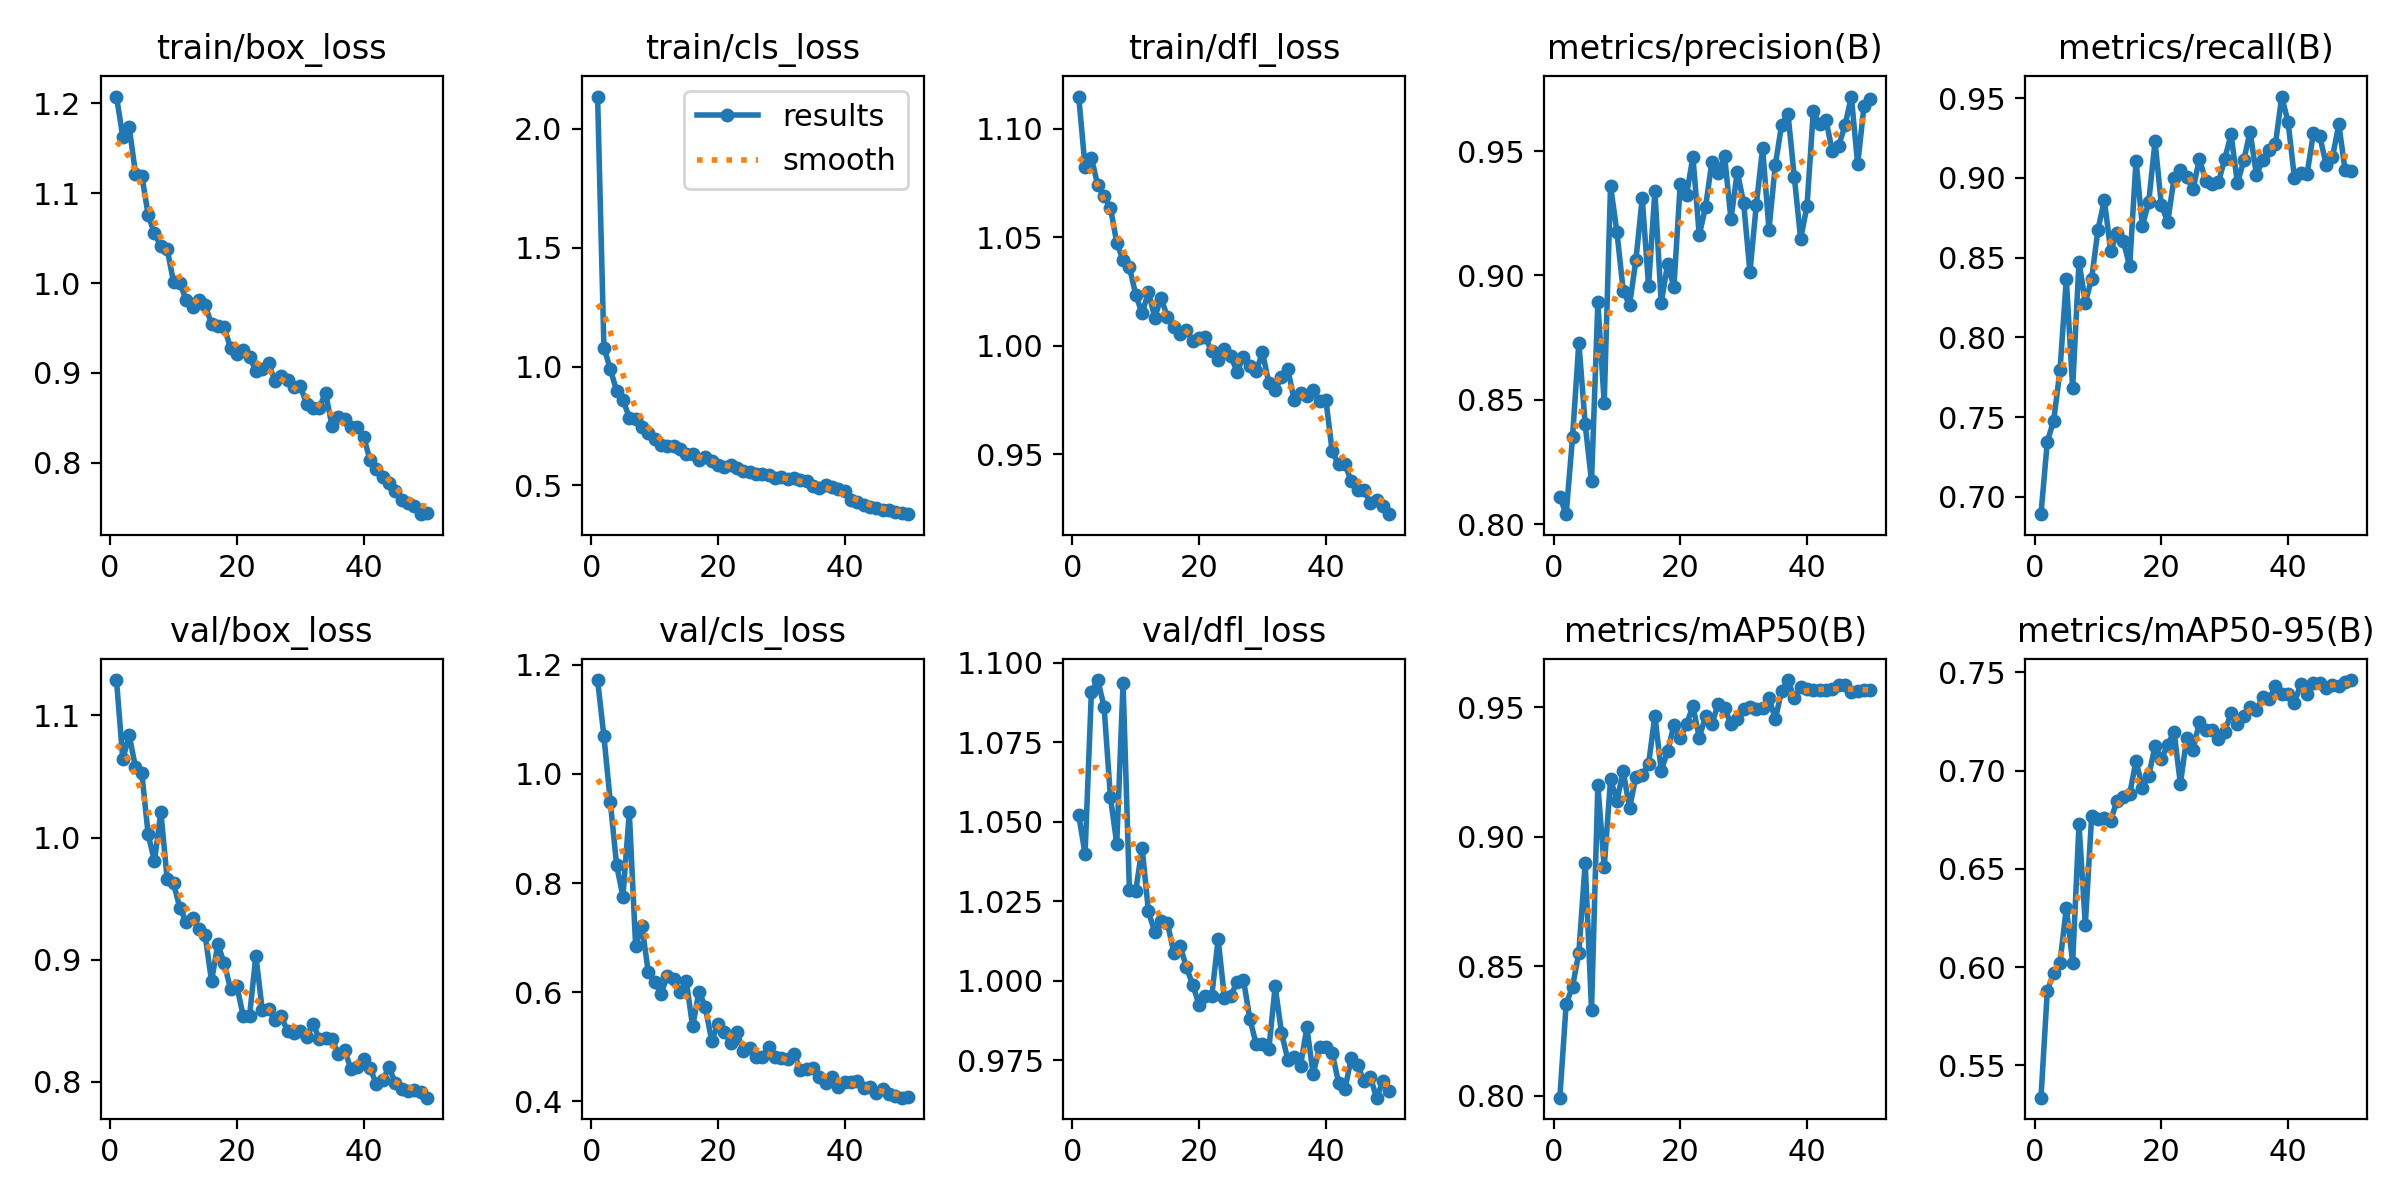

In [34]:
results_path = Path("runs/detect/runs/brain_mri/yolov8n_baseline")

display(IPyImage(filename=str(results_path / "results.png")))

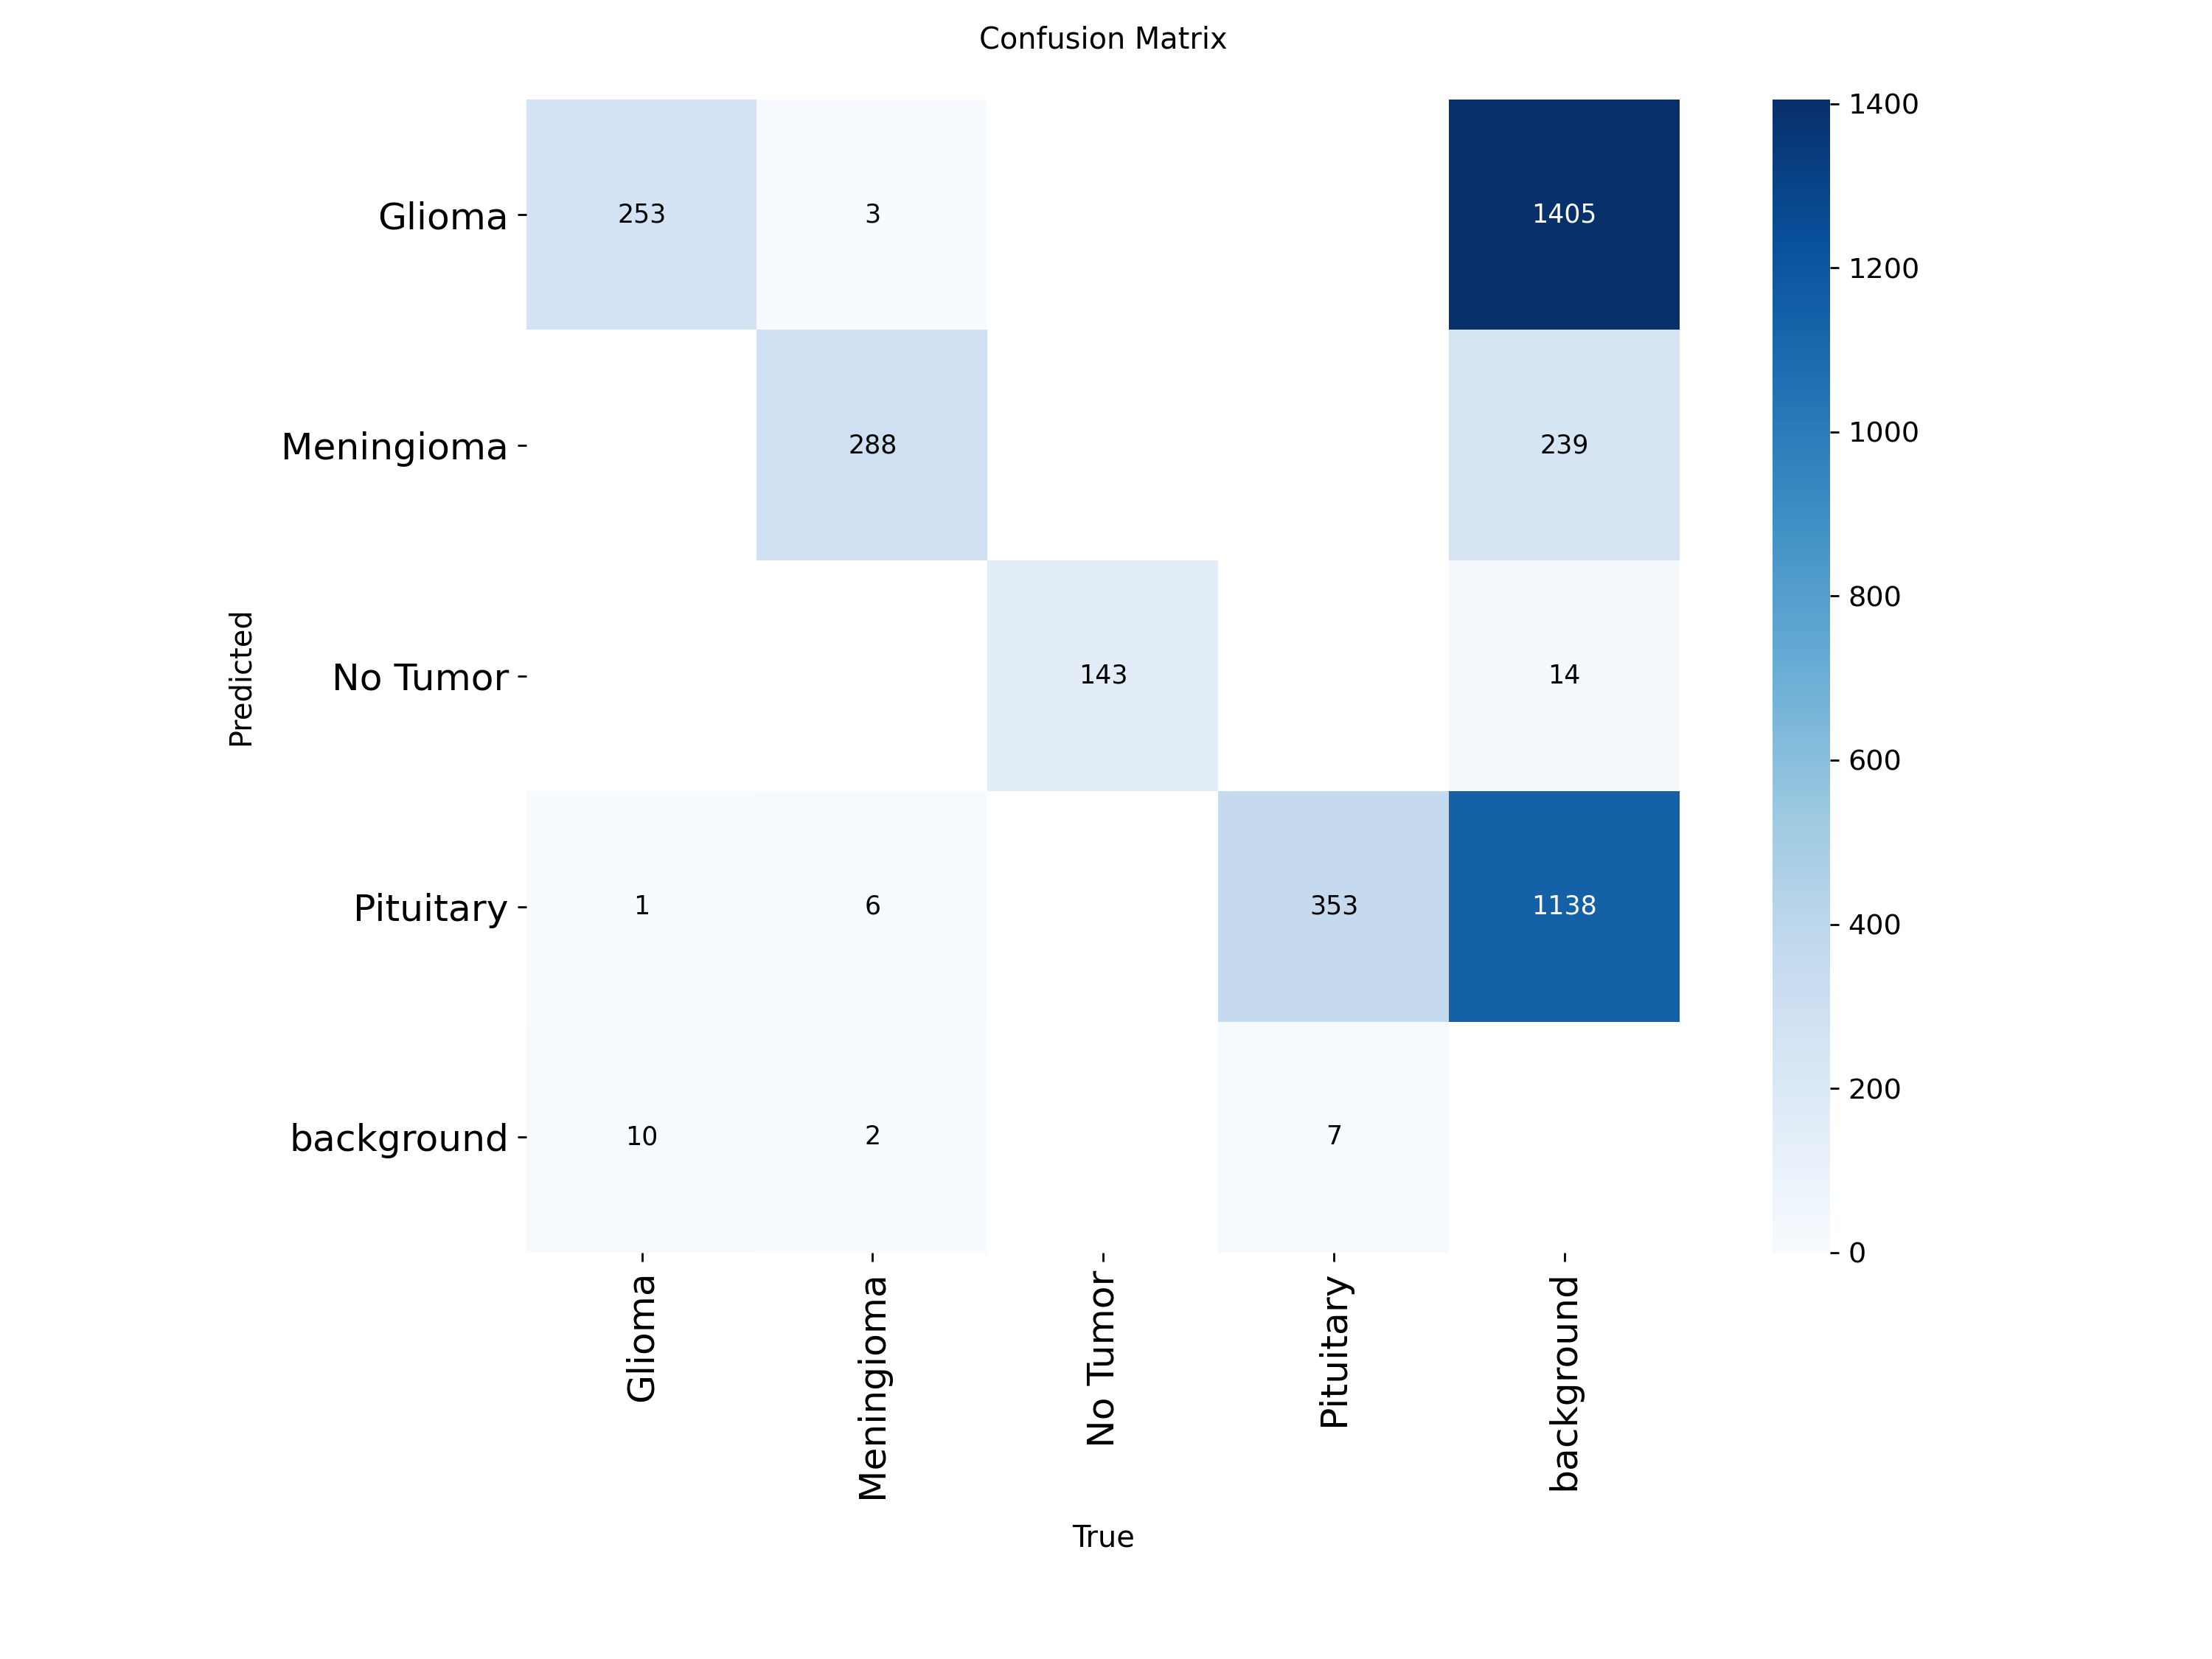

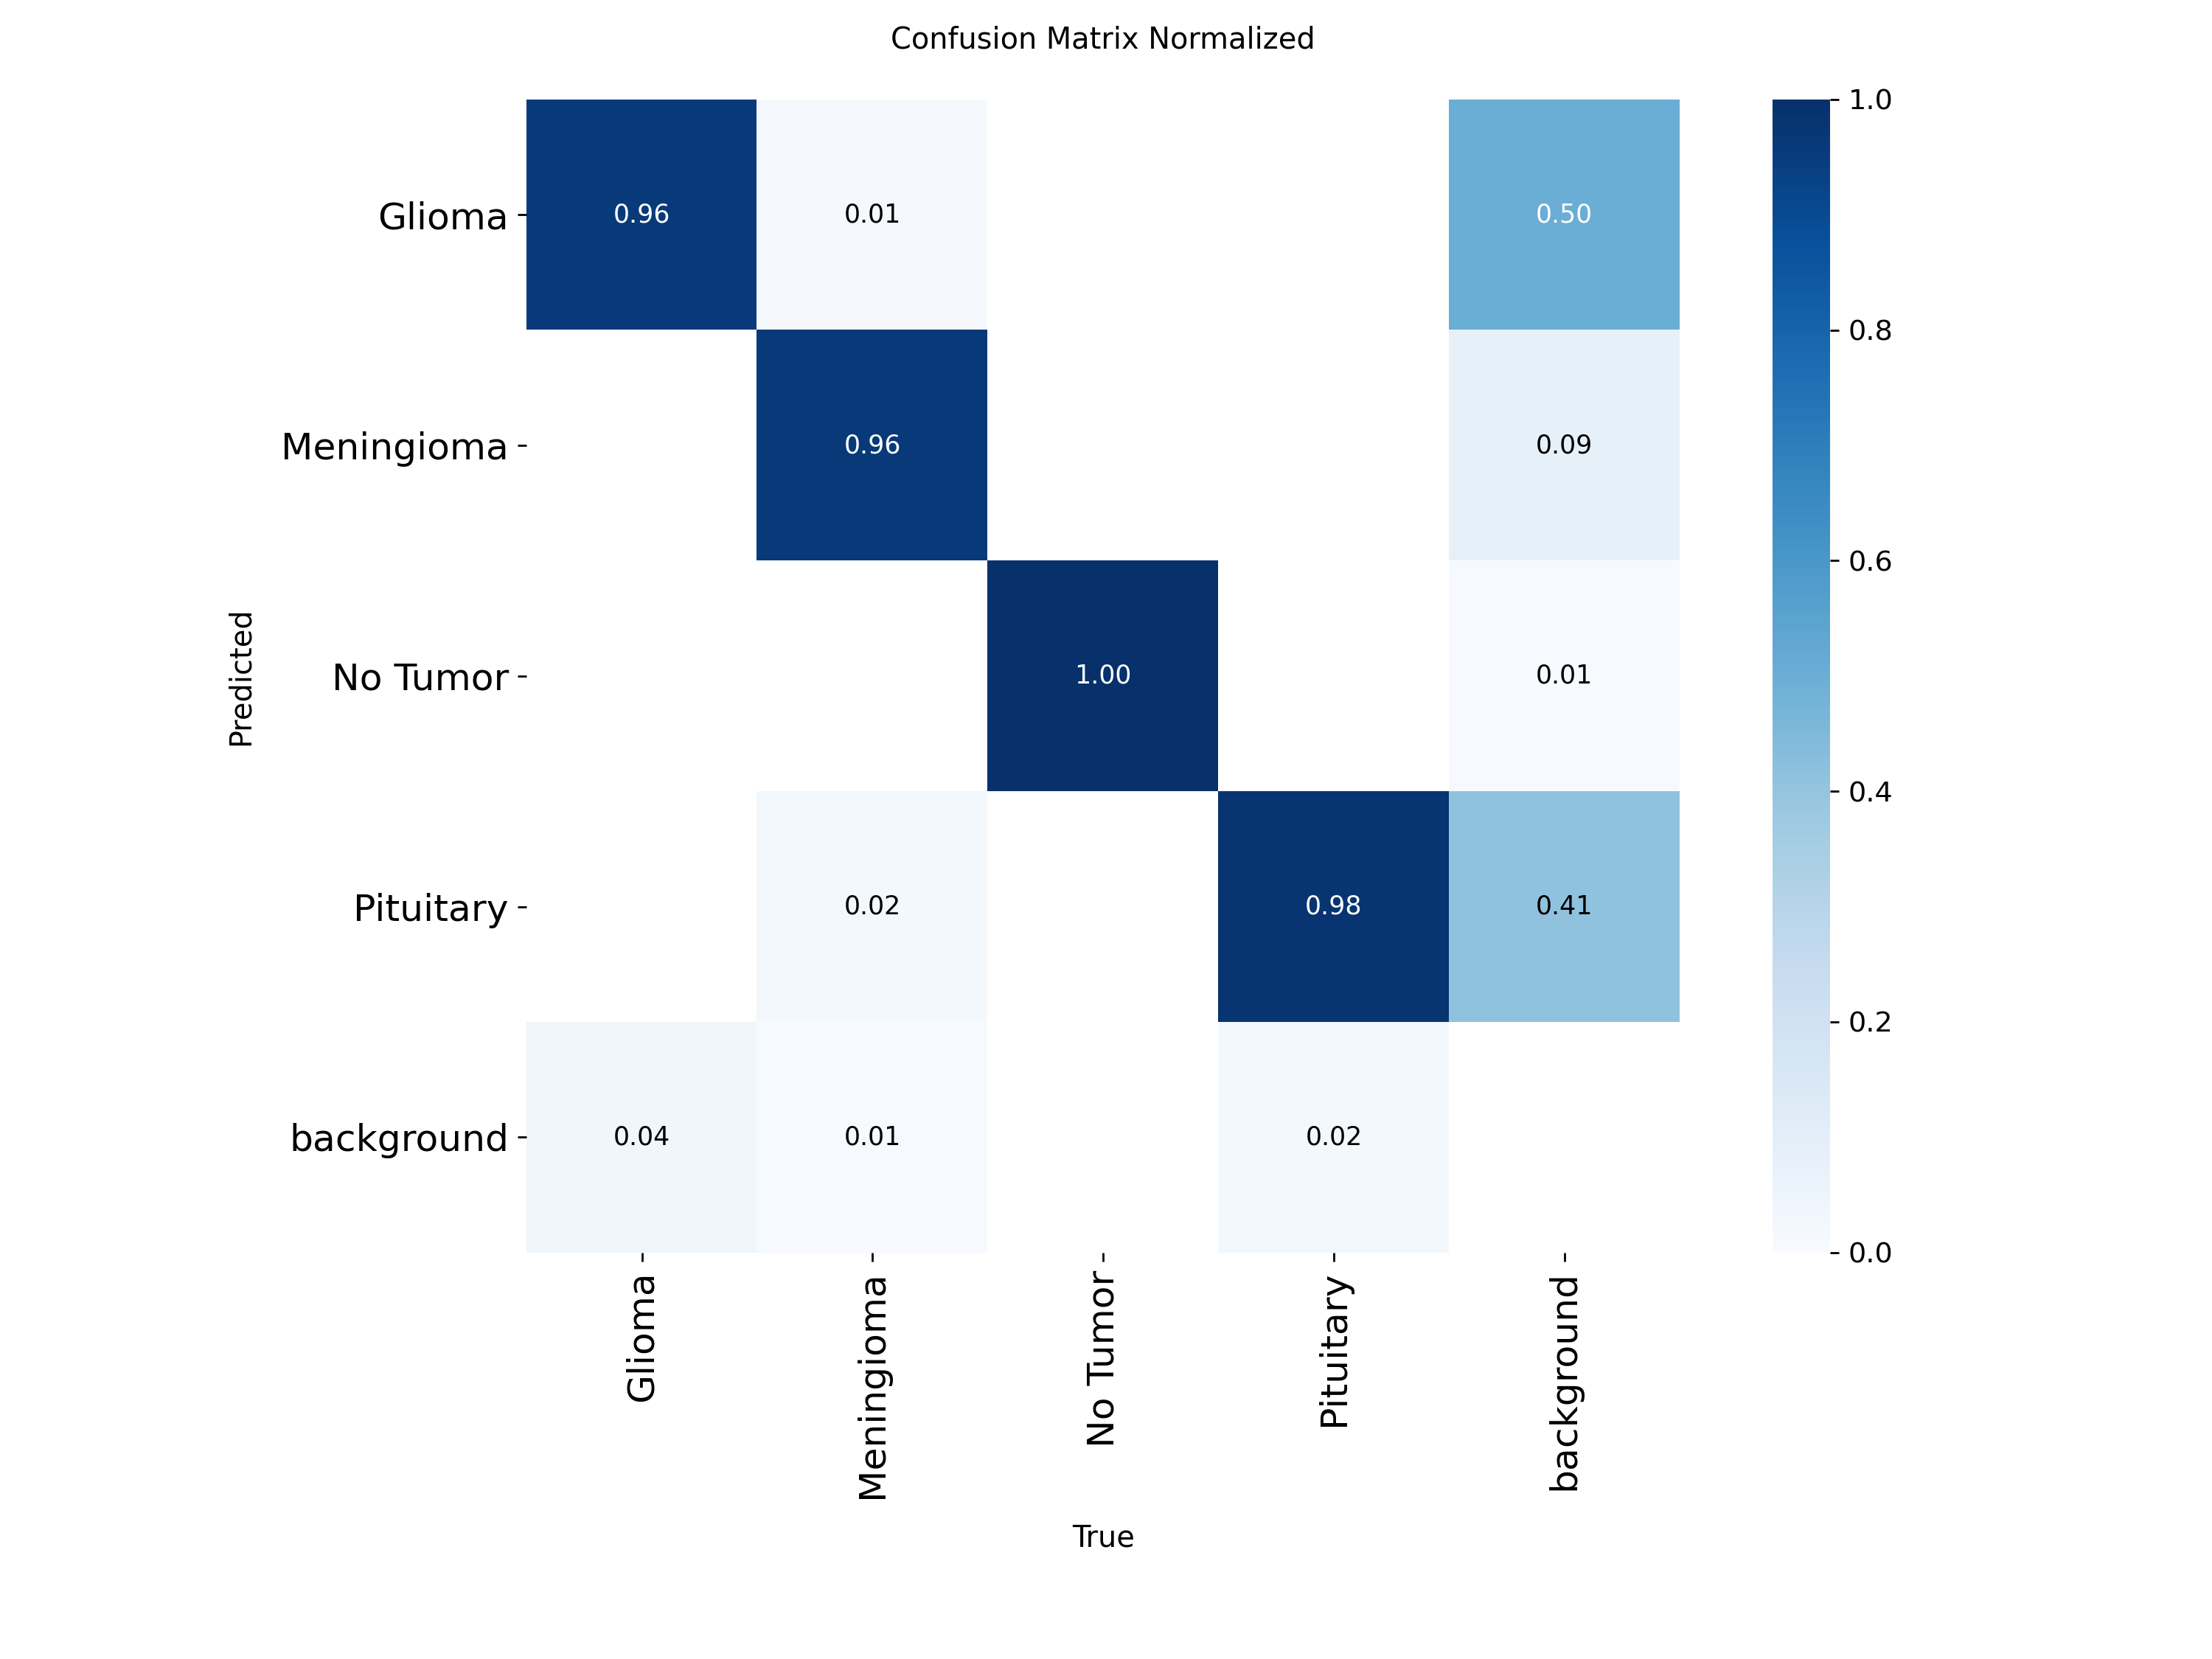

In [35]:
evaluation_path = Path("runs/detect/runs/brain_mri/test_evaluation")

display(IPyImage(filename=str(evaluation_path / "confusion_matrix.png")))
display(IPyImage(filename=str(evaluation_path / "confusion_matrix_normalized.png")))